## Load and format rasters

In [1]:
import os
import subprocess
import geopandas as gpd
import osmnx as ox
import rasterio
from rasterio.enums import Resampling
import matplotlib.pyplot as plt

states = {
    "Ohio": 31,
    "Michigan": 29,
    "Indiana": 20,
    "Pennsylvania": 42,
    "Kentucky": 26,
    "West Virginia": 33,
}

rasters = {
    "canopy_cover": "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/nlcd_tcc_conus_wgs84_v2025-6_20250101_20251231.tif",
    "land_cover": "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/Annual_NLCD_LndCov_2025_CU_C1V2.tif",
    "FctImp": "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/Annual_NLCD_FctImp_2025_CU_C1V2.tif",
}

categorical = ["land_cover"]
DST_CRS = "EPSG:5070"
DST_NODATA = 255  # Safe uint8 nodata for all three layers (valid %: 0-100, classes: 11-95)

In [2]:
# 1. Get 6-state bounding polygon and project directly to target CRS (EPSG:5070)
ox.settings.cache_folder = "/kaggle/working/cache"

region_queries = [f"{state}, USA" for state in states.keys()]
regions_gdf = ox.geocode_to_gdf(region_queries)

# Project to EPSG:5070 BEFORE unioning/buffering so geometry ops happen in meters
regions_gdf = regions_gdf.to_crs(DST_CRS)
master_boundary = regions_gdf.union_all().buffer(0)

cutline_path = "/kaggle/working/six_state_cutline_5070.gpkg"
export_gdf = gpd.GeoDataFrame(geometry=[master_boundary], crs=DST_CRS)
export_gdf.to_file(cutline_path, driver="GPKG")

# Lock in exact target-aligned bounding box (multiples of 30m) so every raster
# gets the exact same width, height, and affine transform.
minx, miny, maxx, maxy = master_boundary.bounds
te_bounds = [
    str(int(minx // 30) * 30),
    str(int(miny // 30) * 30),
    str(int((maxx // 30) + 1) * 30),
    str(int((maxy // 30) + 1) * 30),
]
print(f"Locked 30m aligned bounds (EPSG:5070): {te_bounds}")

Locked 30m aligned bounds (EPSG:5070): ['429030', '1513980', '1781880', '2834850']


In [3]:
# 2. Clip, Reproject, and Align in a Single GDAL Pass
reproj_rasters = {}

for name, src_path in rasters.items():
    out_path = f"/kaggle/working/{name}_clipped_reproj.tiff"
    resample_alg = "near" if name in categorical else "bilinear"

    print(f"Warping & clipping {name} -> {out_path} (resampling={resample_alg})...")

    cmd = [
        "gdalwarp",
        "-overwrite",
        "-t_srs", DST_CRS,
        "-te", *te_bounds,           # Exact shared extent across all rasters
        "-tr", "30", "30",           # Exact 30m x 30m resolution
        "-r", resample_alg,
        "-cutline", cutline_path,
        "-dstnodata", str(DST_NODATA),
        "-ot", "Byte",               # Keep uint8 to save RAM/disk
        "-multi",
        "-wo", "NUM_threads=ALL_CPUS",
        "-co", "COMPRESS=LZW",
        "-co", "TILED=YES",
        "-co", "BLOCKXSIZE=512",
        "-co", "BLOCKYSIZE=512",
        src_path,
        out_path,
    ]

    try:
        subprocess.run(cmd, check=True, capture_output=True, text=True)
        reproj_rasters[f"{name}_clipped_reproj"] = out_path
        print(f"  -> Successfully wrote {out_path}")
    except subprocess.CalledProcessError as e:
        print(f"\nGDAL ERROR ON {name}:")
        print(e.stderr)

# Clean up temporary cutline GeoPackage
if os.path.exists(cutline_path):
    os.remove(cutline_path)

Warping & clipping canopy_cover -> /kaggle/working/canopy_cover_clipped_reproj.tiff (resampling=bilinear)...
  -> Successfully wrote /kaggle/working/canopy_cover_clipped_reproj.tiff
Warping & clipping land_cover -> /kaggle/working/land_cover_clipped_reproj.tiff (resampling=near)...
  -> Successfully wrote /kaggle/working/land_cover_clipped_reproj.tiff
Warping & clipping FctImp -> /kaggle/working/FctImp_clipped_reproj.tiff (resampling=bilinear)...
  -> Successfully wrote /kaggle/working/FctImp_clipped_reproj.tiff


canopy_cover_clipped_reproj  | shape: (44029, 45095) | CRS: EPSG:5070 | nodata: 255.0
land_cover_clipped_reproj    | shape: (44029, 45095) | CRS: EPSG:5070 | nodata: 255.0
FctImp_clipped_reproj        | shape: (44029, 45095) | CRS: EPSG:5070 | nodata: 255.0


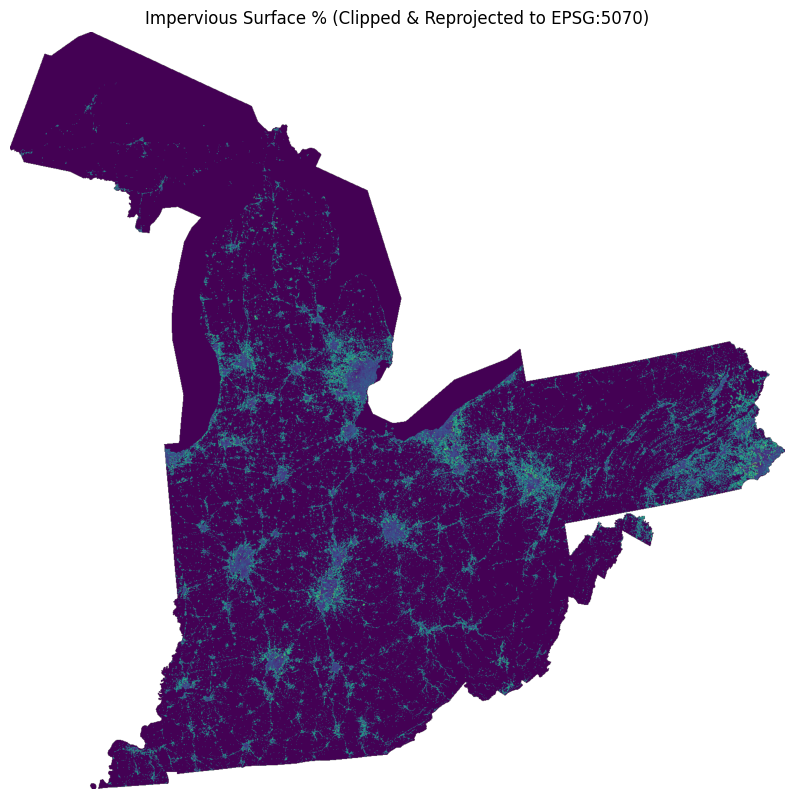

In [4]:
# 3. Verify grid alignment and visualize downsampled output
for name, path in reproj_rasters.items():
    with rasterio.open(path) as src:
        print(f"{name:28s} | shape: {src.shape} | CRS: {src.crs} | nodata: {src.nodata}")

max_size = 1500
with rasterio.open(reproj_rasters["FctImp_clipped_reproj"]) as src:
    scale = min(max_size / src.width, max_size / src.height)
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    image = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.average,
        masked=True,
    )

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(image, cmap="viridis")
ax.set_title("Impervious Surface % (Clipped & Reprojected to EPSG:5070)")
ax.axis("off")
plt.show()